In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import math
import sklearn
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from mpl_toolkits.mplot3d import Axes3D
import statsmodels.api as sm

In [3]:
df = pd.read_csv("C:/Users/Aj Benjamin/Downloads/calories.csv")
print(df)

        User_ID  Gender  Age  Height  Weight  Duration  Heart_Rate  Body_Temp  \
0      14733363    male   68   190.0    94.0      29.0       105.0       40.8   
1      14861698  female   20   166.0    60.0      14.0        94.0       40.3   
2      11179863    male   69   179.0    79.0       5.0        88.0       38.7   
3      16180408  female   34   179.0    71.0      13.0       100.0       40.5   
4      17771927  female   27   154.0    58.0      10.0        81.0       39.8   
...         ...     ...  ...     ...     ...       ...         ...        ...   
14995  15644082  female   20   193.0    86.0      11.0        92.0       40.4   
14996  17212577  female   27   165.0    65.0       6.0        85.0       39.2   
14997  17271188  female   43   159.0    58.0      16.0        90.0       40.1   
14998  18643037    male   78   193.0    97.0       2.0        84.0       38.3   
14999  11751526    male   63   173.0    79.0      18.0        92.0       40.5   

       Calories  
0        

In [4]:
#Check for missing values
print(df.isnull().sum())

User_ID       0
Gender        0
Age           0
Height        0
Weight        0
Duration      0
Heart_Rate    0
Body_Temp     0
Calories      0
dtype: int64


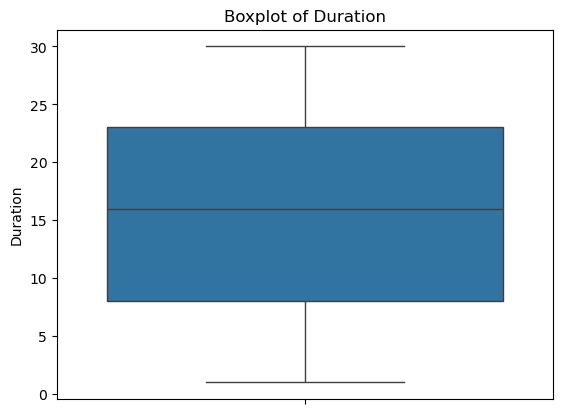

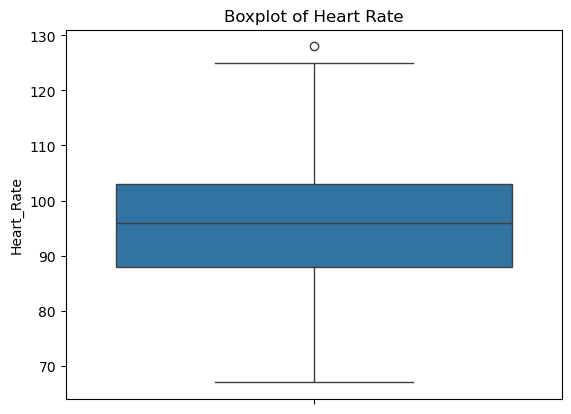

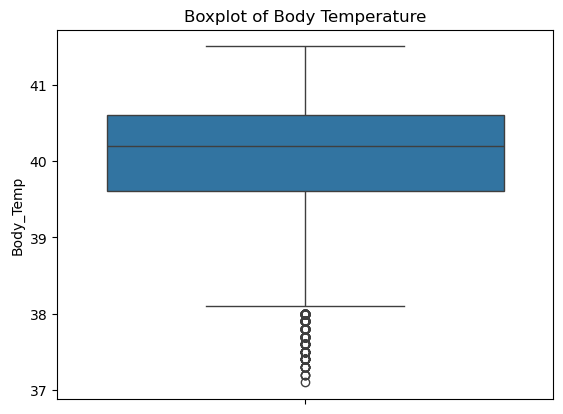

In [5]:
#Check for Outliers
sns.boxplot(df['Duration'])
plt.title('Boxplot of Duration')
plt.show()

sns.boxplot(df['Heart_Rate'])
plt.title('Boxplot of Heart Rate')
plt.show()

sns.boxplot(df['Body_Temp'])
plt.title('Boxplot of Body Temperature')
plt.show()



In [6]:
#Stats
# Using describe() to calculate summary statistics
res = df.describe()
print(res.to_markdown())

|       |         User_ID |        Age |     Height |     Weight |   Duration |   Heart_Rate |   Body_Temp |   Calories |
|:------|----------------:|-----------:|-----------:|-----------:|-----------:|-------------:|------------:|-----------:|
| count | 15000           | 15000      | 15000      | 15000      | 15000      |  15000       | 15000       | 15000      |
| mean  |     1.49774e+07 |    42.7898 |   174.465  |    74.9669 |    15.5306 |     95.5185  |    40.0255  |    89.5395 |
| std   |     2.87285e+06 |    16.9803 |    14.2581 |    15.0357 |     8.3192 |      9.58333 |     0.77923 |    62.457  |
| min   |     1.00012e+07 |    20      |   123      |    36      |     1      |     67       |    37.1     |     1      |
| 25%   |     1.24742e+07 |    28      |   164      |    63      |     8      |     88       |    39.6     |    35      |
| 50%   |     1.49973e+07 |    39      |   175      |    74      |    16      |     96       |    40.2     |    79      |
| 75%   |     1.74493e+0

In [7]:
#Correlation with respect to calories
numerical_cols = df.select_dtypes(include=['number']).columns# will exclude gender data which is a 5050 split
corr_matrix = df[numerical_cols].corr()
print(corr_matrix)

             User_ID       Age    Height    Weight  Duration  Heart_Rate  \
User_ID     1.000000 -0.001827 -0.013520 -0.011603 -0.002751   -0.000457   
Age        -0.001827  1.000000  0.009554  0.090094  0.013247    0.010482   
Height     -0.013520  0.009554  1.000000  0.958451 -0.004625    0.000528   
Weight     -0.011603  0.090094  0.958451  1.000000 -0.001884    0.004311   
Duration   -0.002751  0.013247 -0.004625 -0.001884  1.000000    0.852869   
Heart_Rate -0.000457  0.010482  0.000528  0.004311  0.852869    1.000000   
Body_Temp   0.000923  0.013175  0.001200  0.004095  0.903167    0.771529   
Calories   -0.001661  0.154395  0.017537  0.035481  0.955421    0.897882   

            Body_Temp  Calories  
User_ID      0.000923 -0.001661  
Age          0.013175  0.154395  
Height       0.001200  0.017537  
Weight       0.004095  0.035481  
Duration     0.903167  0.955421  
Heart_Rate   0.771529  0.897882  
Body_Temp    1.000000  0.824558  
Calories     0.824558  1.000000  


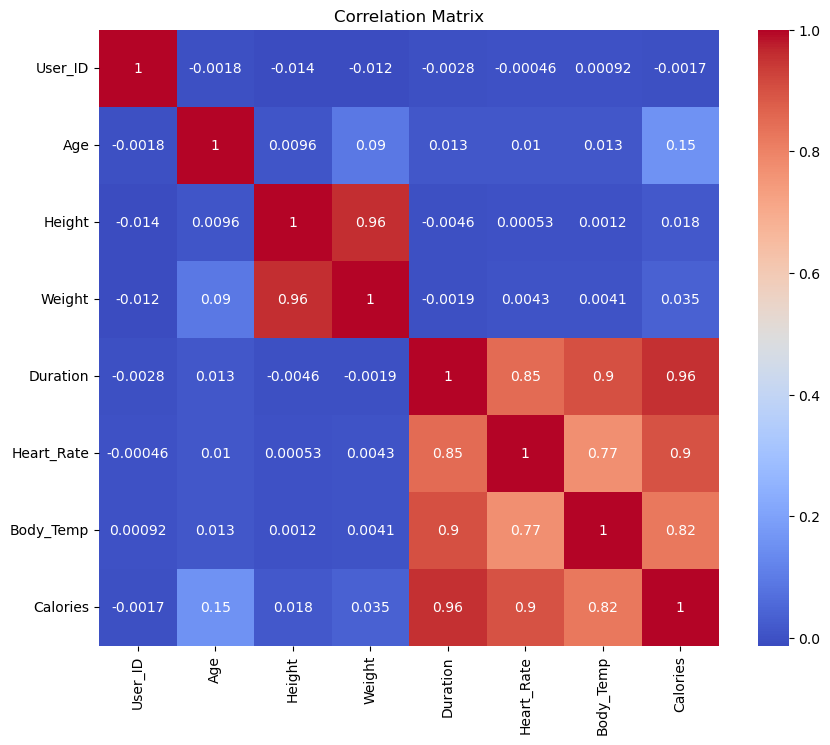

In [8]:
# Plotting the correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()


In [9]:
#Select Features
selected_features = ['Duration', 'Heart_Rate', 'Body_Temp']
X = df[selected_features]
y = df['Calories']


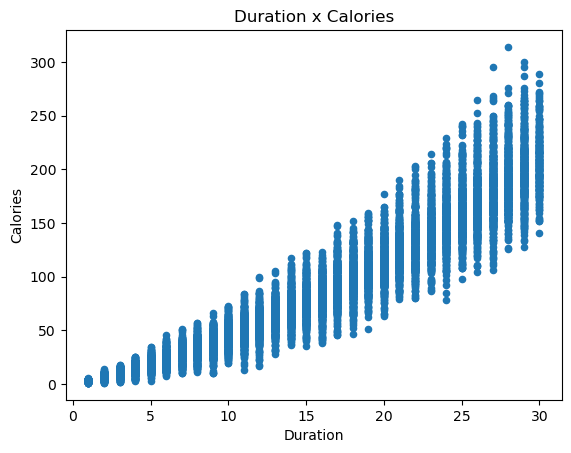

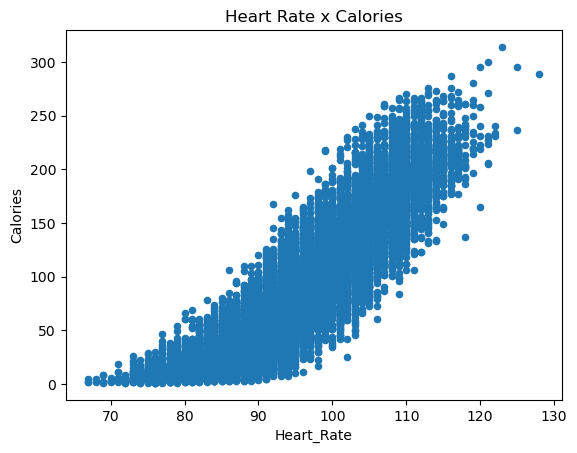

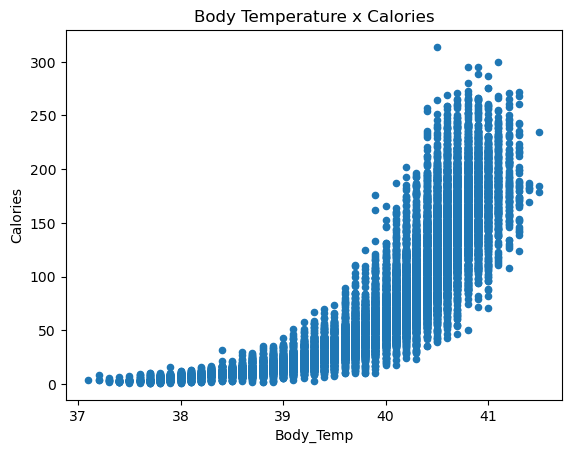

In [10]:
#Explore plots
df.plot(x='Duration', y='Calories', kind='scatter')
plt.title('Duration x Calories')
plt.show()
df.plot(x='Heart_Rate', y='Calories', kind='scatter')
plt.title('Heart Rate x Calories')
plt.show()
df.plot(x='Body_Temp', y='Calories', kind='scatter')
plt.title('Body Temperature x Calories')
plt.show()



In [11]:
##Scale Data
# Initialize the StandardScaler object
scaler = StandardScaler()
# Fit the scaler to the data and transform it
X_scaled = scaler.fit_transform(X)
# Print the scaled data
print(X_scaled)

[[ 1.61912727  0.98940395  0.99402302]
 [-0.1839901  -0.15846102  0.3523425 ]
 [-1.26586052 -0.78456918 -1.70103518]
 ...
 [ 0.05642555 -0.57586646  0.09567029]
 [-1.62648399 -1.20197462 -2.21437961]
 [ 0.2968412  -0.36716374  0.60901471]]


In [13]:
#Multiple Linear Regression'
#Unscaled

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#Scaled
#X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# The 'LinearRegression' model is initialized and fitted to the training data.
model = LinearRegression()
model.fit(X_train, y_train)

# The model is used to predict the target variable for the test set.
y_pred = model.predict(X_test)
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R-squared:", r2_score(y_test, y_pred))


Mean Squared Error: 216.08235682070807
R-squared: 0.9464584932015652


In [14]:
# model using statsmodel for summary
newmodel=sm.OLS(y,X).fit()
print(newmodel.summary())

                                 OLS Regression Results                                
Dep. Variable:               Calories   R-squared (uncentered):                   0.981
Model:                            OLS   Adj. R-squared (uncentered):              0.981
Method:                 Least Squares   F-statistic:                          2.588e+05
Date:                Thu, 13 Nov 2025   Prob (F-statistic):                        0.00
Time:                        18:34:12   Log-Likelihood:                         -61933.
No. Observations:               15000   AIC:                                  1.239e+05
Df Residuals:                   14997   BIC:                                  1.239e+05
Df Model:                           3                                                  
Covariance Type:            nonrobust                                                  
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------

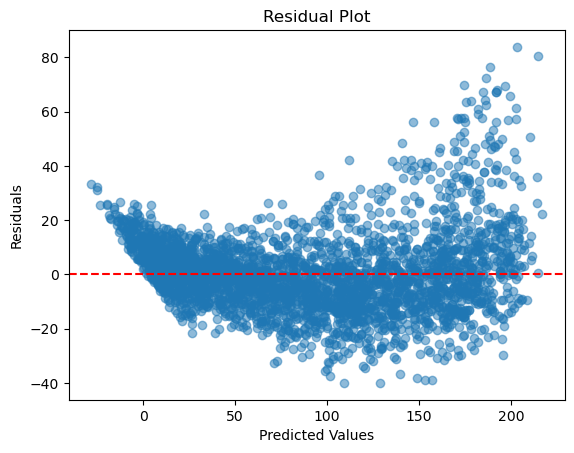

In [15]:
# Residual Plot
residuals = y_test - y_pred
plt.scatter(y_pred, residuals, alpha=0.5)
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.axhline(y=0, color='red', linestyle='--')
plt.show()


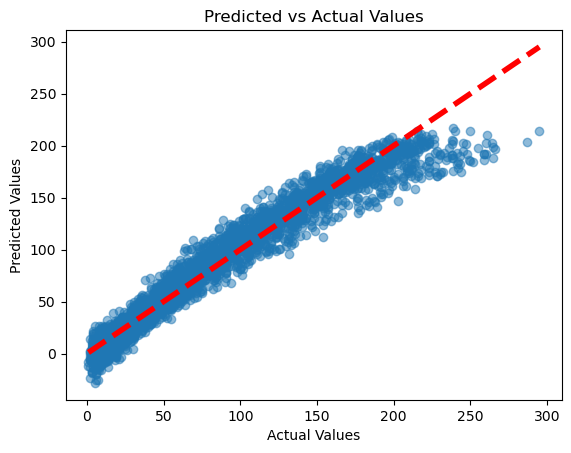

In [16]:
# Predicted vs Actual Plot
plt.scatter(y_test, y_pred, alpha=0.5)
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Predicted vs Actual Values')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=4)
plt.show()

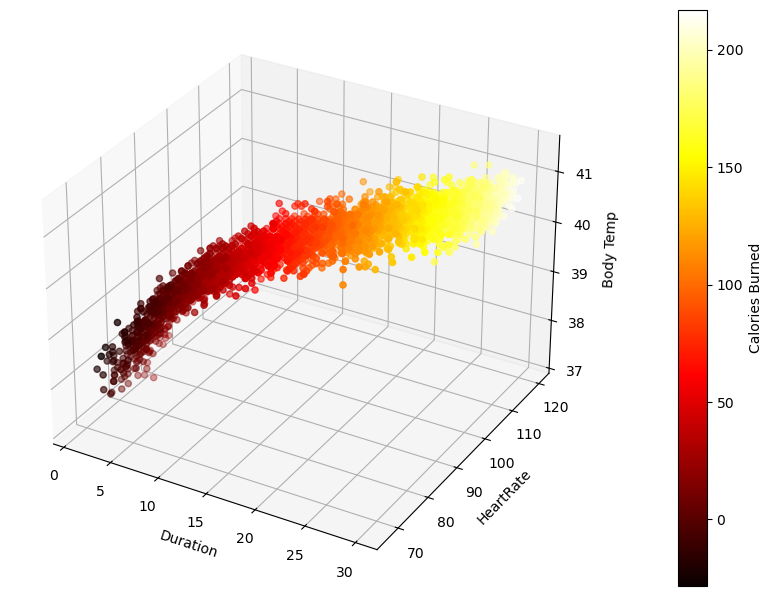

In [17]:
#4d plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
fig.subplots_adjust(top=1.1,bottom=-.1,right=3)

a=np.array(X_test)
x = (a[:,0])
y =(a[:,1])
z = (a[:,2])
c = y_pred

ax.set_xlabel("Duration")
ax.set_ylabel("HeartRate")
ax.set_zlabel("Body Temp")

img = ax.scatter(x, y, z, c=c, cmap=plt.hot())
fig.colorbar(img,label='Calories Burned')
plt.show()

      Feature       VIF
0    Duration  8.056450
1  Heart_Rate  3.668295
2   Body_Temp  5.426412


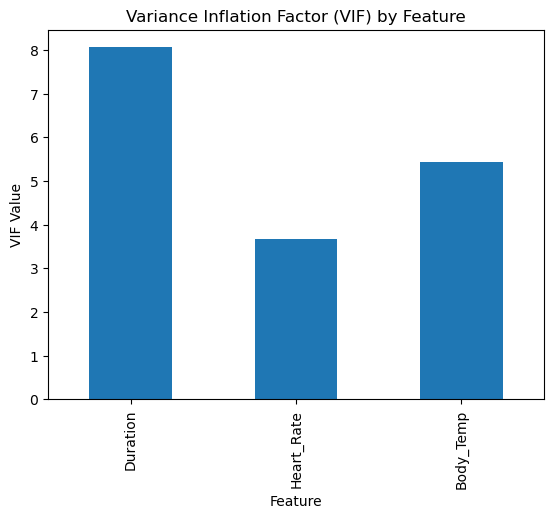

In [18]:
#Variance Inflation Factor
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()
vif_data['Feature'] = selected_features
vif_data['VIF'] = [variance_inflation_factor(X_scaled, i) for i in range(X_scaled.shape[1])]
print(vif_data)

# Bar Plot for VIF Values
vif_data.plot(kind='bar', x='Feature', y='VIF', legend=False)
plt.title('Variance Inflation Factor (VIF) by Feature')
plt.ylabel('VIF Value')
plt.show()